# MOLECULAR DYNAMICS COMPARED WITH MAXWELL-BOLTZMANN

In [3]:
from matplotlib import pyplot as plt
import numpy as np
from numba import jit

## Set Parameters

In [24]:
#number of particles
N = 16

#length of box
L = 10.0

#mass of argon molecule
mass = 1.0  #mass of argon is actually 40 amu

#time of integration
dt = 0.02
tmin = 0.
tmax = 50.
t = np.linspace(tmin, tmax, int((tmax - tmin)/dt + 1))  

x = np.zeros((len(t), 2, N))  #1st row for previous location 2nd row for present location
y = np.zeros((len(t), 2, N))

x_new = np.zeros((1,N)) #future positions
y_new = np.zeros((1,N))

v_x = np.zeros((len(t), 1, N))  #velocities
v_y = np.zeros((len(t), 1, N))


#molecules are spaced in a grid 2 sigma apart
i = 0
deltar = 1e-2

for alpha in range(2,9,2):
    for beta in range(2,9,2):
        x[0, 1, i] = alpha + 2.*(np.random.uniform(0,1)-0.5)*deltar
        y[0, 1, i] = beta + 2.*(np.random.uniform(0,1)-0.5)*deltar
        
        i = i + 1
        
v0 = 1.0 

for i in range(0,N):
    v_x[0, 0, i] = 2.*(np.random.uniform(0,1) - 0.5)*v0
    v_y[0, 0, i] = 2.*(np.random.uniform(0,1) - 0.5)*v0

#keep the mean zero
v_x[0,0,:] = v_x[0,0,:] - np.mean(v_x[0,0,:])
v_y[0,0,:] = v_y[0,0,:] - np.mean(v_y[0,0,:])

#reverse Euler to find previous locations
x[0, 0, :] = x[0, 1, :] - v_x[0, 0, :]*dt
y[0, 0, :] = y[0, 1, :] - v_y[0, 0, :]*dt


In [25]:
len(t)

2501

## Time Evolve

In [26]:


@jit(nopython = True)
def time_evolve(x, y, v_x, v_y, x_new, y_new):
    F = np.zeros((2,N))  #1st row for x component 2nd row for y component
    for i in range(0,len(t)-1):

        #CALCULATE FORCES
        for n in range(0,N): #particle n under focus
            for m in range(0,N):   #particle m is everything that is not n.
                if m!=n:
                    r_x=x[i,1,n]-x[i,1,m]
                    r_y=y[i,1,n]-y[i,1,m]
                    #periodic boundary conditions
                    if r_x>L/2:
                        r_x=r_x-L
                    if r_x<-L/2:
                        r_x=r_x+L
                    if r_y>L/2:
                        r_y=r_y-L
                    if r_y<-L/2:
                        r_y=r_y+L
                
                    r_nm=np.sqrt(r_x**2.0 +r_y**2.0)
                    #if r_nm<3:  #cutoff is 3 sigma
                    F_nm_x = 24*((2/(r_nm**13))-(1/(r_nm**7)))*(r_x)/(np.abs(r_nm))
                    F_nm_y = 24*((2/(r_nm**13))-(1/(r_nm**7)))*(r_y)/(np.abs(r_nm))
                    F[0,n] = F[0,n] + F_nm_x #total x component force on nth particle
                    F[1,n] = F[1,n] + F_nm_y #total y component force on nth particle
                    
        
        #UPDATE POSITIONS  
        for n in range(0,N):
            x_new[0,n]=2*x[i,1,n]-x[i,0,n]+(F[0,n]/mass)*dt**2 
            y_new[0,n]=2*y[i,1,n]-y[i,0,n]+(F[1,n]/mass)*dt**2
            
            F[0,n] = 0. #re-intializing forces for next time step computation.
            F[1,n] = 0.
            
            #periodic boundary conditions to t+1,t,t-1 because Verlet Method for next time step involves these quantities so they must follow meaningfully as a pair
            
            if x_new[0,n]>L:
                x_new[0,n] = x_new[0,n]-L
                x[i+1,1,n] = x[i,1,n]-L
                x[i+1,0,n] = x[i,0,n]-L
            elif x_new[0,n]<0:
                x_new[0,n] = x_new[0,n]+L
                x[i+1,1,n] = x[i,1,n]+L
                x[i+1,0,n] = x[i,0,n]+L
            else:
                x[i+1,1,n] = x[i,1,n]
                x[i+1,0,n] = x[i,0,n]
                
     
            if y_new[0,n]>L:
                y_new[0,n] = y_new[0,n]-L
                y[i+1,1,n] = y[i,1,n]-L
                y[i+1,0,n] = y[i,0,n]-L
            elif y_new[0,n]<0:
                y_new[0,n] = y_new[0,n]+L
                y[i+1,1,n] = y[i,1,n]+L
                y[i+1,0,n] = y[i,0,n]+L
            else:
                y[i+1,1,n] = y[i,1,n]
                y[i+1,0,n] = y[i,0,n]
                
            
            v_x[i+1,0,n]=(x_new[0,n]-x[i+1,0,n])/(2*dt)
            v_y[i+1,0,n]=(y_new[0,n]-y[i+1,0,n])/(2*dt)
            
            #shifting values for future time step calculations....
            x[i+1,0,n] = x[i+1,1,n]
            x[i+1,1,n] = x_new[0,n]

            y[i+1,0,n] = y[i+1,1,n]
            y[i+1, 1,n] = y_new[0,n]


        if i%100==0:
            print('At time:'+str(i+1))
    


In [27]:
time_evolve(x, y, v_x, v_y, x_new, y_new )

At time:1
At time:101
At time:201
At time:301
At time:401
At time:501
At time:601
At time:701
At time:801
At time:901
At time:1001
At time:1101
At time:1201
At time:1301
At time:1401
At time:1501
At time:1601
At time:1701
At time:1801
At time:1901
At time:2001
At time:2101
At time:2201
At time:2301
At time:2401


$$ k T = \frac{1}{2}m< v_x^2 + v_y^2>$$

## Visualize Frame

In [140]:
def plot_frame(index, ax):
    
    molecules = ax[0]
    maxwell_boltzmann = ax[1]
    
    molecules.scatter(x[index, 1, :], y[index, 1, :], c='red', zorder = 3)
    molecules.set_xlim([0-L/10,L+L/10])
    molecules.set_ylim([0-L/10, L+L/10])
    molecules.set_xticks([])
    molecules.set_yticks([])

    # arrows in the direction of each velocity (quiver); scale tunes arrow length
    molecules.quiver(x[index, 1, :], y[index, 1, :],
                     v_x[index, 0, :], v_y[index, 0, :],
                     color='yellow', angles='xy', scale_units='xy',
                     scale=2.0, width=0.003, zorder=2)

    # white border on the molecules panel
    for spine in molecules.spines.values():
        spine.set_color('white')
        spine.set_linewidth(1.5)

    ####################################################################################################
    '''
    v_numerical = np.sqrt(v_x[index, 0, :]**2. + v_y[index,0, :]**2.)
    vs = np.linspace(0, np.max(v_numerical)*3, 1000)
    maxwell_boltzmann.hist(v_numerical, density = True, color ='yellow', label ='Simulation')
    maxwell_boltzmann.plot(vs, (mass*vs/(T[index]))*np.exp(-mass*vs**2./(2*T[index])), linestyle='dashed', c='red', label='Maxwell-Boltzmann Fit')
    maxwell_boltzmann.legend(loc=1, fontsize=15)
    maxwell_boltzmann.set_ylabel(r'$P(v)$', c='white', fontsize=15)
    maxwell_boltzmann.set_xlabel(r'$v$', c='white', fontsize=15)
    '''
    # pool velocities from an equilibrated start up to the current frame
    burn_in = 1000 #this is t=20
    lo = min(burn_in, index)                       # don't pool the transient
    vx_pool = v_x[lo:index+1, 0, :].ravel()
    vy_pool = v_y[lo:index+1, 0, :].ravel()
    v_pool = np.sqrt(vx_pool**2 + vy_pool**2)

    # single temperature from the pooled equilibrium set (kT, since T here = 1/2 m<v^2>)
    kT = 0.5 * mass * np.mean(vx_pool**2 + vy_pool**2)

    bins = np.linspace(0, np.max(v_pool)*1.05, 30)  # fixed, sensible range
    maxwell_boltzmann.hist(v_pool, bins=bins, density=True,
                           color='yellow', label='Simulation')

    vs = np.linspace(0, np.max(v_pool)*1.2, 400)    # NOT *10
    maxwell_boltzmann.plot(vs, (mass*vs/kT)*np.exp(-mass*vs**2/(2*kT)),
                           linestyle='dashed', c='red', label='Maxwell-Boltzmann')

    maxwell_boltzmann.legend(loc=1)
    maxwell_boltzmann.set_ylabel(r'$P(v)$', c='white', fontsize=15)
    maxwell_boltzmann.set_xlabel(r'$v$', c='white', fontsize=15)



    # white ticks + tick labels so they're visible on black
    maxwell_boltzmann.tick_params(colors='white')

    # white border on the distribution panel
    for spine in maxwell_boltzmann.spines.values():
        spine.set_color('white')
        spine.set_linewidth(1.5)

   
    

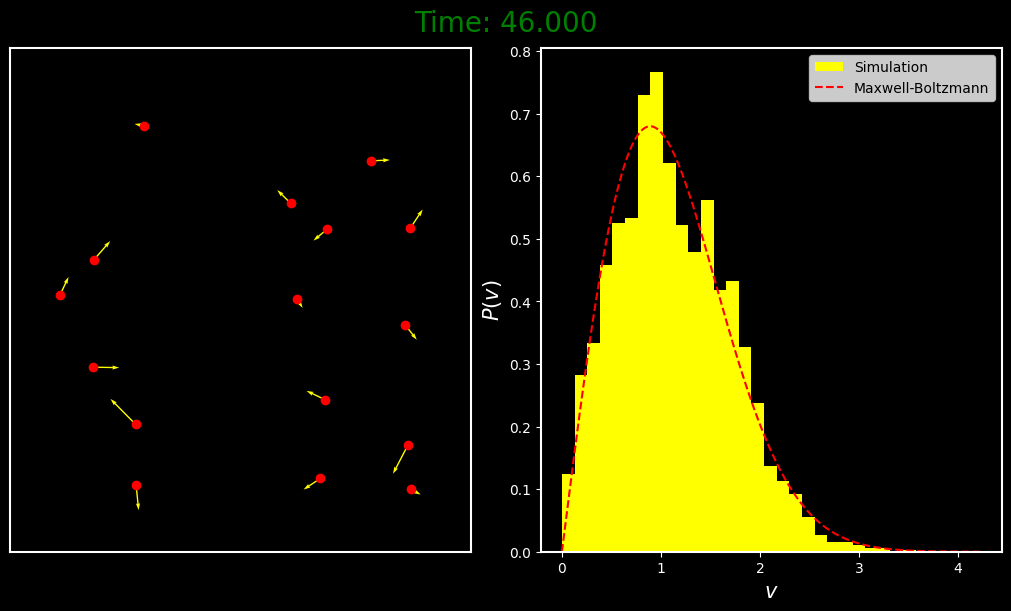

In [142]:
fig, ax = plt.subplots(1,2, figsize=(10, 6), constrained_layout=True)
fig.suptitle('Time: '+str("%.3f" %(t[2300])), c='green', fontsize =20)
fig.patch.set_facecolor('black')
ax[0].set_facecolor('black')
ax[1].set_facecolor('black')
plot_frame(2300,ax)
plt.show()

## Make Movie

In [133]:
from matplotlib.animation import PillowWriter

In [134]:
metadata = dict(title='Movie', artist ='ayush_roy')
writer = PillowWriter(fps=10, metadata = metadata)

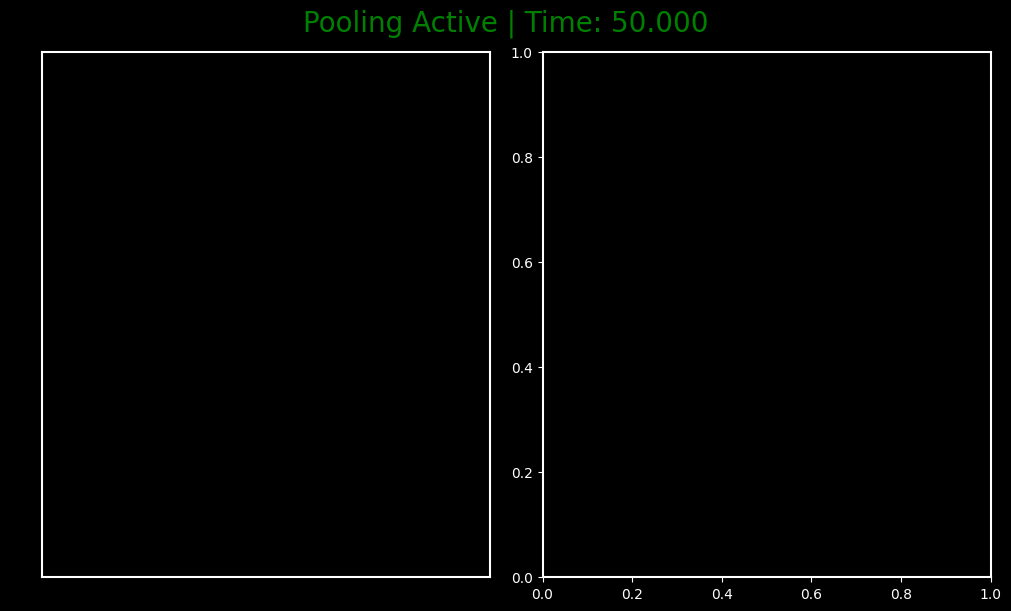

In [143]:
fig, ax = plt.subplots(1,2, figsize=(10, 6), constrained_layout=True)
fig.patch.set_facecolor('black')
ax[0].set_facecolor('black')
ax[1].set_facecolor('black')

with writer.saving(fig, 'molecular_dynamics.gif',100):
    for i in range(0, len(t)):
        if i%10 == 0:
            if i<=1000:
                fig.suptitle('Time: '+str("%.3f" %(t[i])), c='white', fontsize = 20)
            else:
                fig.suptitle('Pooling Active | Time: '+str("%.3f" %(t[i])), c='green', fontsize = 20)
            plot_frame(i, ax)
            writer.grab_frame()
            ax[0].clear()
            ax[1].clear()